<a href="https://colab.research.google.com/github/ZiyuCao421/26-CP5046-SIN-CAM-TR3-ICT-Project-1-Analysis-and-Design/blob/main/Mouse_Dynamics_Lightweight_3_Features.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mouse Dynamics: Lightweight Three-Feature Classification

This notebook uses exactly three movement-derived features: `avg_d`, `avg_tv`, and `avg_a`. It preserves the dataset's existing `label` values and does not infer or overwrite labels from filenames. Results and conclusions must be based on a completed run.

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 42
# 修改为 Google Colab 的上传路径
DATA_DIR = Path("/content")
FILE_PATTERN = "*3MouseMovement_MCQ_Segment.csv"
FEATURES = ["avg_d", "avg_tv", "avg_a"]
LABEL_COLUMN = "label"
REQUIRED_COLUMNS = FEATURES + [LABEL_COLUMN]

sns.set_theme(style="whitegrid")
print(f"Data directory: {DATA_DIR}")
print(f"Selected features: {FEATURES}")

Data directory: /content
Selected features: ['avg_d', 'avg_tv', 'avg_a']


## 1. Load and validate the source files

The loader reports the files and their original labels. It intentionally does not use a filename to replace a `label` value.

In [5]:
if not DATA_DIR.exists():
    raise FileNotFoundError(f"DATA_DIR does not exist: {DATA_DIR}")

csv_files = sorted(DATA_DIR.glob(FILE_PATTERN))
if not csv_files:
    raise FileNotFoundError(f"No files matching {FILE_PATTERN!r} were found in {DATA_DIR}")

frames = []
audit_rows = []
for csv_path in csv_files:
    source_df = pd.read_csv(csv_path)
    missing_columns = [column for column in REQUIRED_COLUMNS if column not in source_df.columns]
    if missing_columns:
        raise ValueError(f"{csv_path.name} is missing required columns: {missing_columns}")

    source_df = source_df.drop(columns=["Unnamed: 0"], errors="ignore")
    source_df["source_file"] = csv_path.name
    frames.append(source_df)
    audit_rows.append({
        "source_file": csv_path.name,
        "rows": len(source_df),
        "labels_in_file": sorted(source_df[LABEL_COLUMN].dropna().unique().tolist()),
        "columns_after_index_drop": len(source_df.columns)
    })

raw_df = pd.concat(frames, ignore_index=True)
file_audit = pd.DataFrame(audit_rows)
display(file_audit)
print(f"Loaded {len(csv_files)} files and {len(raw_df):,} raw rows.")
print("Observed labels before cleaning:", sorted(raw_df[LABEL_COLUMN].dropna().unique().tolist()))

,source_file,rows,labels_in_file,columns_after_index_drop
0,User10_Calib_3MouseMovement_MCQ_Segment.csv,211,[10],69
1,User1_Calib_3MouseMovement_MCQ_Segment.csv,264,[1],69
2,User2_Calib_3MouseMovement_MCQ_Segment.csv,286,[2],69
3,User3_Calib_3MouseMovement_MCQ_Segment.csv,234,[3],69
4,User4_Calib_3MouseMovement_MCQ_Segment.csv,122,[4],69
5,User5_Calib_3MouseMovement_MCQ_Segment.csv,181,[5],69
6,User6_Calib_3MouseMovement_MCQ_Segment.csv,172,[6],69
7,User7_Calib_3MouseMovement_MCQ_Segment.csv,159,[7],69
8,User8_Calib_3MouseMovement_MCQ_Segment.csv,184,[5],69
9,User9_Calib_3MouseMovement_MCQ_Segment.csv,189,[9],69


Loaded 10 files and 2,002 raw rows.
Observed labels before cleaning: [1, 2, 3, 4, 5, 6, 7, 9, 10]


## 2. Clean exactly the three selected features

Only the selected features are coerced to numeric. Rows with a missing label, missing selected feature, or non-finite selected feature are removed and counted. The source CSV files are not changed.

In [6]:
working_df = raw_df.copy()
working_df[FEATURES] = working_df[FEATURES].apply(pd.to_numeric, errors="coerce")
working_df[FEATURES] = working_df[FEATURES].replace([np.inf, -np.inf], np.nan)

quality_summary = pd.DataFrame({
    "dtype": working_df[FEATURES + [LABEL_COLUMN]].dtypes.astype(str),
    "missing": working_df[FEATURES + [LABEL_COLUMN]].isna().sum(),
    "unique_values": working_df[FEATURES + [LABEL_COLUMN]].nunique(dropna=True)
})
display(quality_summary)

valid_rows = working_df[FEATURES + [LABEL_COLUMN]].notna().all(axis=1)
clean_df = working_df.loc[valid_rows, FEATURES + [LABEL_COLUMN, "source_file"]].copy()
removed_rows = len(working_df) - len(clean_df)

assert clean_df[FEATURES].shape[1] == 3
assert np.isfinite(clean_df[FEATURES].to_numpy()).all()
assert clean_df[FEATURES].shape[0] == clean_df[LABEL_COLUMN].shape[0]

print(f"Rows removed during selected-feature cleaning: {removed_rows:,}")
print(f"Rows available for modelling: {len(clean_df):,}")
print(f"Full-row duplicates before cleaning: {raw_df.duplicated().sum():,}")
display(clean_df[LABEL_COLUMN].value_counts().sort_index().rename("count").to_frame())

,dtype,missing,unique_values
avg_d,float64,0,1345
avg_tv,float64,0,2001
avg_a,float64,0,2001
label,int64,0,9


Rows removed during selected-feature cleaning: 0
Rows available for modelling: 2,002
Full-row duplicates before cleaning: 0


,count
label,
1,264
2,286
3,234
4,122
5,365
6,172
7,159
9,189
10,211


## 3. Lightweight exploratory data analysis

These charts describe the supplied data. They do not establish causation or deployment-level authentication performance.

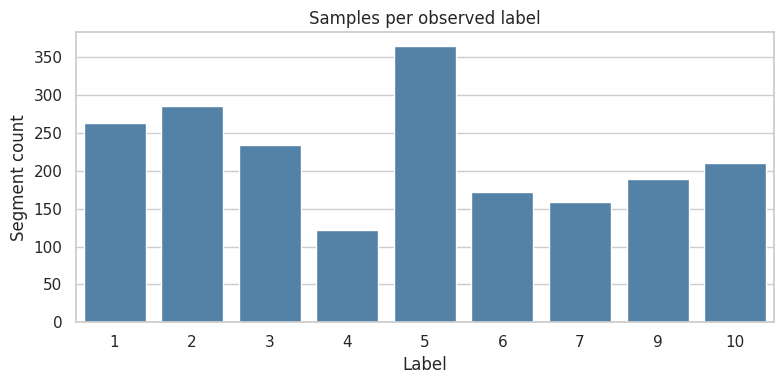

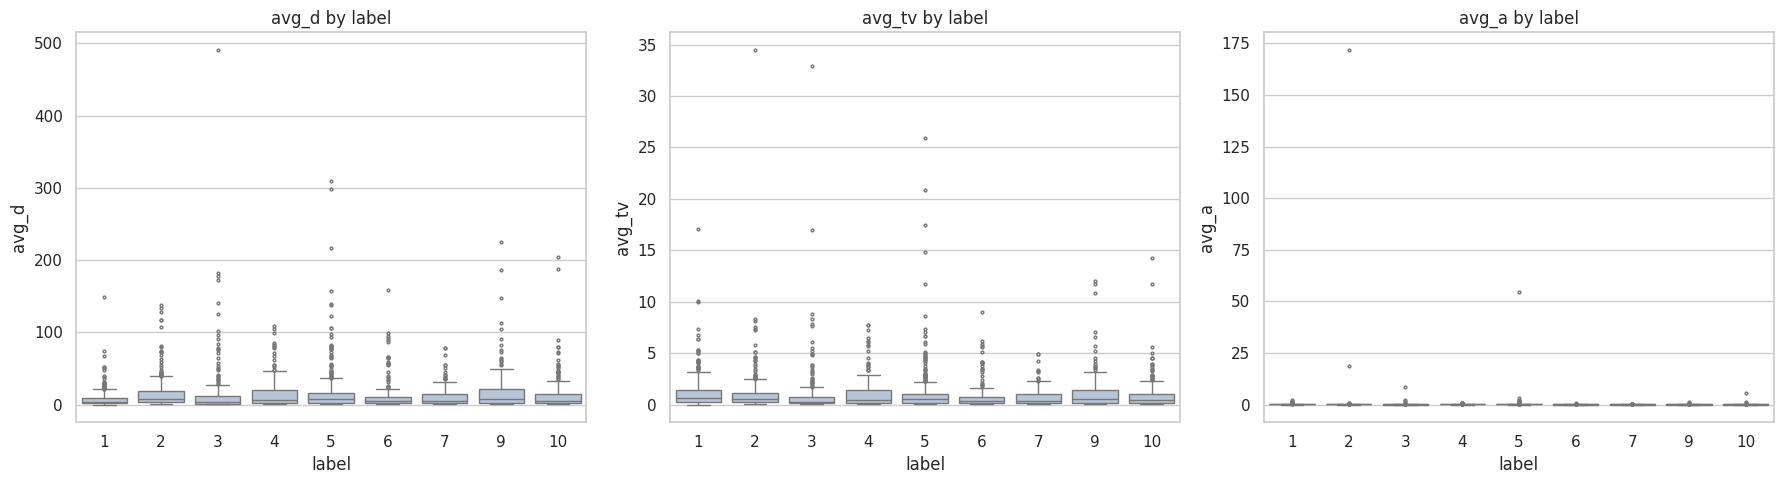

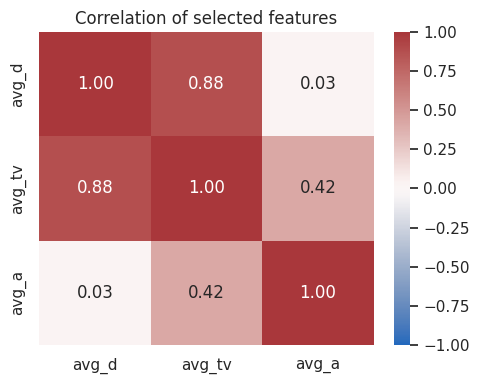

In [7]:
class_counts = clean_df[LABEL_COLUMN].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=class_counts.index.astype(str), y=class_counts.values, ax=ax, color="steelblue")
ax.set(title="Samples per observed label", xlabel="Label", ylabel="Segment count")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for feature, ax in zip(FEATURES, axes):
    sns.boxplot(data=clean_df, x=LABEL_COLUMN, y=feature, ax=ax, color="lightsteelblue", fliersize=2)
    ax.set_title(f"{feature} by label")
plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 4))
sns.heatmap(clean_df[FEATURES].corr(), annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1)
plt.title("Correlation of selected features")
plt.tight_layout()
plt.show()

## 4. One stratified train/test split

Every model below uses this same split, so their comparison is fair. A segment-level random split can place related movements from one collection session in both sets. If a real session identifier becomes available, add a separate group-based validation experiment rather than inventing one.

In [8]:
X = clean_df[FEATURES].copy()
y = clean_df[LABEL_COLUMN].copy()

if y.nunique() < 2:
    raise ValueError("At least two observed labels are required for supervised classification.")
if y.value_counts().min() < 2:
    raise ValueError("Each observed label needs at least two rows for a stratified split.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")
split_counts = pd.concat([
    y_train.value_counts().sort_index().rename("train"),
    y_test.value_counts().sort_index().rename("test")
], axis=1).fillna(0).astype(int)
display(split_counts)

Training rows: 1,601; test rows: 401


,train,test
label,,
1,211,53
2,229,57
3,187,47
4,98,24
5,292,73
6,137,35
7,127,32
9,151,38
10,169,42


## 5. Train a sanity baseline and two candidate models

`DummyClassifier` is a non-learning reference. The two candidate models are an RBF SVC, which scales inputs inside a pipeline, and a Random Forest, which supplies a nonlinear tree-based comparison. No hyperparameters are tuned on the test set.

In [9]:
models = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "RBF SVC": Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced"))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, class_weight="balanced"
    )
}

predictions = {}
for model_name, model in models.items():
    model.fit(X_train, y_train)
    predictions[model_name] = model.predict(X_test)

print("Training complete.")

Training complete.


## 6. Evaluate and compare the models

Macro-averaged precision, recall, and F1 give each observed label equal weight. This notebook does not calculate a single FPR/FAR/FRR because the current task is multi-class classification rather than a defined binary verification protocol.

,model,accuracy,macro_precision,macro_recall,macro_f1
0,Random Forest,0.272,0.241,0.246,0.241
1,RBF SVC,0.200,0.180,0.184,0.153
2,Dummy (most frequent),0.182,0.020,0.111,0.034



RBF SVC classification report
              precision    recall  f1-score   support

           1       0.85      0.53      0.65        53
           2       0.29      0.25      0.27        57
           3       0.13      0.68      0.22        47
           4       0.15      0.08      0.11        24
           5       0.00      0.00      0.00        73
           6       0.00      0.00      0.00        35
           7       0.05      0.06      0.05        32
           9       0.14      0.05      0.08        38
          10       0.00      0.00      0.00        42

    accuracy                           0.20       401
   macro avg       0.18      0.18      0.15       401
weighted avg       0.20      0.20      0.17       401



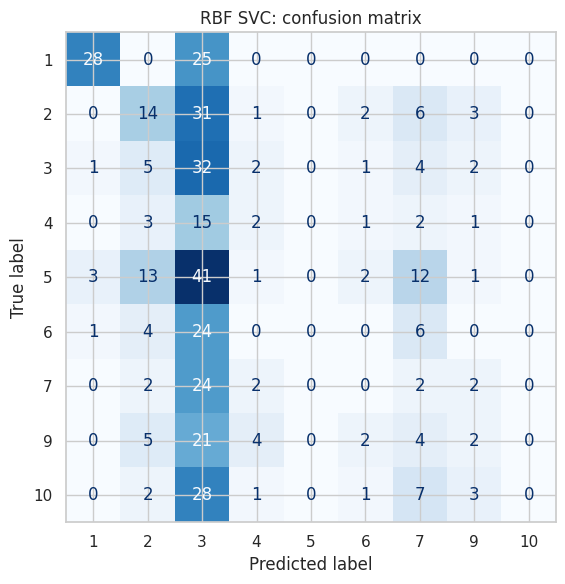


Random Forest classification report
              precision    recall  f1-score   support

           1       0.77      0.87      0.81        53
           2       0.28      0.32      0.30        57
           3       0.24      0.23      0.24        47
           4       0.31      0.21      0.25        24
           5       0.17      0.18      0.18        73
           6       0.03      0.03      0.03        35
           7       0.05      0.03      0.04        32
           9       0.13      0.13      0.13        38
          10       0.18      0.21      0.20        42

    accuracy                           0.27       401
   macro avg       0.24      0.25      0.24       401
weighted avg       0.26      0.27      0.26       401



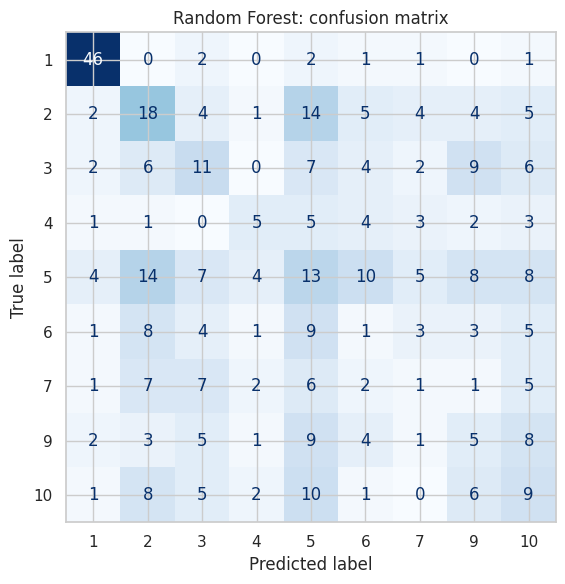

In [10]:
labels = np.sort(y.unique())
metric_rows = []
for model_name, y_pred in predictions.items():
    metric_rows.append({
        "model": model_name,
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_test, y_pred, average="macro", zero_division=0),
    })

results = pd.DataFrame(metric_rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
display(results.style.format({
    "accuracy": "{:.3f}", "macro_precision": "{:.3f}",
    "macro_recall": "{:.3f}", "macro_f1": "{:.3f}"
}))

for model_name in ["RBF SVC", "Random Forest"]:
    y_pred = predictions[model_name]
    print(f"\n{model_name} classification report")
    print(classification_report(y_test, y_pred, labels=labels, zero_division=0))
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=labels), display_labels=labels).plot(
        ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(f"{model_name}: confusion matrix")
    plt.tight_layout()
    plt.show()

## 7. Discussion after execution

Complete these points only after running the notebook:

1. Which candidate model has the highest observed macro F1, and how does it compare with the dummy baseline?
2. Which observed labels are most frequently confused in the confusion matrices?
3. What does the distance–speed–acceleration feature set capture, and what behavioural information does it omit?
4. How could the segment-level split, device/context variation, label distribution, and lack of session identifiers limit generalisation?

Do not claim that this small experiment is a deployment-ready authentication or fraud-detection system.